# Pokétwo Spawn Rates

Pokétwo is a Discord bot that spawns a wild Pokémon after enough chat activity. This notebook uses the bot's public data to check if spawns are fully random, and what makes a species common or rare

Each spawn is one weighted random pick over every catchable species

```python
random.choices(pool, weights=[x.abundance for x in pool], k=1)[0]
```

A species' chance per spawn is its weight divided by the sum of all weights

## Tools used
- Python
- pandas
- matplotlib and seaborn
- scikit-learn
- statsmodels

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score

# Chart colors, taken from my site
PINK = '#ff9ecf'
BLUE = '#8fd0ff'
DEEP_PINK = '#ff5fa8'
DEEP_BLUE = '#5aa9e6'
CARD = '#121210'
PANEL = '#0d0d0d'
BORDER = '#393939'
TEXT = '#adb0b0'

DATA_PATH = Path('.')
ASSET_PATH = DATA_PATH / 'assets'

# Chart theme
font_manager.fontManager.addfont(ASSET_PATH / 'VT323-Regular.ttf')
sns.set_theme(style='dark', palette=[PINK, BLUE, DEEP_PINK, DEEP_BLUE], rc={
    'font.family': ['VT323', 'DejaVu Sans'],
    'font.size': 15,
    'figure.facecolor': CARD,
    'axes.facecolor': PANEL,
    'axes.edgecolor': BORDER,
    'axes.labelcolor': TEXT,
    'axes.labelsize': 17,
    'axes.titlecolor': PINK,
    'axes.titlesize': 24,
    'axes.titlepad': 12,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': '#1f1f1f',
    'text.color': TEXT,
    'xtick.color': TEXT,
    'ytick.color': TEXT,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'legend.facecolor': CARD,
    'legend.edgecolor': BORDER,
    'patch.edgecolor': CARD,
    'axes.spines.top': False,
    'axes.spines.right': False,
})


def decorate():
    fig = plt.gcf()

    for ax in fig.axes:
        if ax.get_title():
            ax.set_title('⊹ ˚ ♡  ' + ax.get_title().upper() + '  ♡ ˚ ⊹')
    fig.tight_layout()


def label_bars(fmt, **text_options):
    # Writes each bar's value above it, so the tiny bars can still be read
    ax = plt.gca()
    ax.bar_label(ax.containers[-1], fmt=fmt, padding=3, **text_options)
    ax.margins(y=0.12)

pokemon_df = pd.read_csv(
    DATA_PATH / 'data' / 'pokemon.csv',
    dtype={'evo.to': str, 'evo.from': str},
    low_memory=False,
)
pokemon_df.head()

,id,dex_number,region,slug,description,credit,enabled,catchable,abundance,gender_rate,...,base.sdef,base.spd,evo.mega,evo.mega_x,evo.mega_y,is_form,form_item,hatch_counter,spawn_time,spawn_season
0,1,1,kanto,bulbasaur,"For some time after its birth, it grows by tak...",NaN,1.0,1.0,512.0,1,...,65,45,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN
1,2,2,kanto,ivysaur,"When the bud on its back starts swelling, a sw...",NaN,1.0,1.0,256.0,1,...,80,60,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN
2,3,3,kanto,venusaur,"After a rainy day, the flower on its back smel...",NaN,1.0,1.0,96.0,1,...,100,80,10033.0,NaN,NaN,NaN,NaN,20.0,NaN,NaN
3,4,4,kanto,charmander,The fire on the tip of its tail is a measure o...,NaN,1.0,1.0,512.0,1,...,50,65,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN
4,5,5,kanto,charmeleon,"In the rocky mountains where Charmeleon live, ...",NaN,1.0,1.0,256.0,1,...,65,80,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN


## Data cleaning

Only species with a non-empty `catchable` value are in the spawn pool. The flag columns are blank or 1, so they are converted to 0 and 1

In [2]:
# Keep a copy of raw dimensions for context
raw_shape = pokemon_df.shape
print('Raw shape:', raw_shape)

# Any non-empty catchable value puts the species in the spawn pool
df = pokemon_df[pokemon_df['catchable'].notna()].copy()

# The source already has a weight column for body weight, so it is renamed first
df = df.rename(columns={
    'weight': 'body_weight',
    'abundance': 'weight',
    'name.en': 'name',
    'type.0': 'type_1',
    'type.1': 'type_2',
})
df['weight'] = df['weight'].astype(int)
df['region'] = df['region'].str.title()

# Flag cleanup
for col in ['mythical', 'legendary', 'ultra_beast', 'is_form']:
    df[col] = (df[col].fillna(0) > 0).astype(int)

# Base stat total
stat_cols = ['base.hp', 'base.atk', 'base.def', 'base.satk', 'base.sdef', 'base.spd']
df['base_stat_total'] = df[stat_cols].sum(axis=1)

# Spawn chance
total_weight = df['weight'].sum()
df['spawn_chance'] = df['weight'] / total_weight
df['one_in_n'] = total_weight / df['weight']

print('Cleaned shape:', df.shape)
print('Total weight:', total_weight)

Raw shape: (1743, 42)
Cleaned shape: (1322, 45)
Total weight: 345833


## Evolution stage and rarity class

The source has no stage column, so it is built by following `evo.from` up to the base form and `evo.to` down to the last form. Baby Pokémon get their own class and do not count as a stage, so Pikachu is stage 1 of 2. Mythical, Legendary and Ultra Beast flags take priority over stage

In [3]:
all_ids = set(pokemon_df['id'])

# Evolution links
evo_from = {}
evo_to = {}
for pid, parent, kids in zip(pokemon_df['id'], pokemon_df['evo.from'], pokemon_df['evo.to']):
    if pd.notna(parent) and parent.isdigit() and int(parent) in all_ids:
        evo_from[pid] = int(parent)
    if pd.notna(kids):
        evo_to[pid] = [int(k) for k in kids.split() if int(k) in all_ids]


# Baby Pokémon by Pokédex number, from the is_baby flag in PokeAPI
baby_dex = [
    172, 173, 174, 175, 236, 238, 239, 240, 298, 360,
    406, 433, 438, 439, 440, 446, 447, 458, 848,
]
baby_ids = set(pokemon_df.loc[pokemon_df['dex_number'].isin(baby_dex), 'id'])


def get_stage(pid, seen=()):
    parent = evo_from.get(pid)
    # A baby does not count as a stage, so the count stops there
    if parent is None or parent in seen or parent in baby_ids:
        return 1
    return 1 + get_stage(parent, seen + (pid,))


def get_stages_after(pid, seen=()):
    kids = [k for k in evo_to.get(pid, []) if k not in seen]
    if len(kids) == 0:
        return 0
    return 1 + max(get_stages_after(k, seen + (pid,)) for k in kids)


df['stage'] = df['id'].apply(get_stage)
df.loc[df['dex_number'].isin(baby_dex), 'stage'] = 0
df['chain_length'] = df['stage'] + df['id'].apply(get_stages_after)

# Stage label
df['class'] = 'Stage ' + df['stage'].astype(str) + ' of ' + df['chain_length'].astype(str)
df.loc[df['chain_length'] == 1, 'class'] = 'Single stage'
df.loc[df['stage'] == 0, 'class'] = 'Baby'
df['rarity_group'] = 'Normal'

# Rarity flags, the last one applied wins
for col, label in [('ultra_beast', 'Ultra Beast'), ('legendary', 'Legendary'), ('mythical', 'Mythical')]:
    df.loc[df[col] == 1, 'class'] = label
    df.loc[df[col] == 1, 'rarity_group'] = label

df[['name', 'region', 'type_1', 'type_2', 'class', 'weight', 'spawn_chance', 'one_in_n']].head(10)

,name,region,type_1,type_2,class,weight,spawn_chance,one_in_n
0,Bulbasaur,Kanto,Grass,Poison,Stage 1 of 3,512,0.001480,675.455078
1,Ivysaur,Kanto,Grass,Poison,Stage 2 of 3,256,0.000740,1350.910156
2,Venusaur,Kanto,Grass,Poison,Stage 3 of 3,96,0.000278,3602.427083
3,Charmander,Kanto,Fire,NaN,Stage 1 of 3,512,0.001480,675.455078
4,Charmeleon,Kanto,Fire,NaN,Stage 2 of 3,256,0.000740,1350.910156
5,Charizard,Kanto,Fire,Flying,Stage 3 of 3,96,0.000278,3602.427083
6,Squirtle,Kanto,Water,NaN,Stage 1 of 3,512,0.001480,675.455078
7,Wartortle,Kanto,Water,NaN,Stage 2 of 3,256,0.000740,1350.910156
8,Blastoise,Kanto,Water,NaN,Stage 3 of 3,96,0.000278,3602.427083
9,Caterpie,Kanto,Bug,NaN,Stage 1 of 3,1536,0.004441,225.151693


## Spawn rates by class

How much of the spawn pool each class takes up, and how heavy a typical species in that class is

In [4]:
class_order = [
    'Baby',
    'Stage 1 of 3', 'Stage 2 of 3', 'Stage 3 of 3',
    'Stage 1 of 2', 'Stage 2 of 2',
    'Single stage',
    'Legendary', 'Mythical', 'Ultra Beast',
]

class_summary = pd.DataFrame({
    'species': df.groupby('class').size(),
    'total_weight': df.groupby('class')['weight'].sum(),
    'avg_weight': df.groupby('class')['weight'].mean(),
}).reindex(class_order)

class_summary['share_of_spawns'] = class_summary['total_weight'] / total_weight * 100
class_summary['one_every_n_spawns'] = total_weight / class_summary['total_weight']
class_summary.round(2)

,species,total_weight,avg_weight,share_of_spawns,one_every_n_spawns
class,,,,,
Baby,20,4128,206.40,1.19,83.78
Stage 1 of 3,109,124200,1139.45,35.91,2.78
Stage 2 of 3,110,37605,341.86,10.87,9.20
Stage 3 of 3,133,10176,76.51,2.94,33.99
Stage 1 of 2,248,111764,450.66,32.32,3.09
Stage 2 of 2,331,32666,98.69,9.45,10.59
Single stage,208,24339,117.01,7.04,14.21
Legendary,105,560,5.33,0.16,617.56
Mythical,47,362,7.70,0.10,955.34


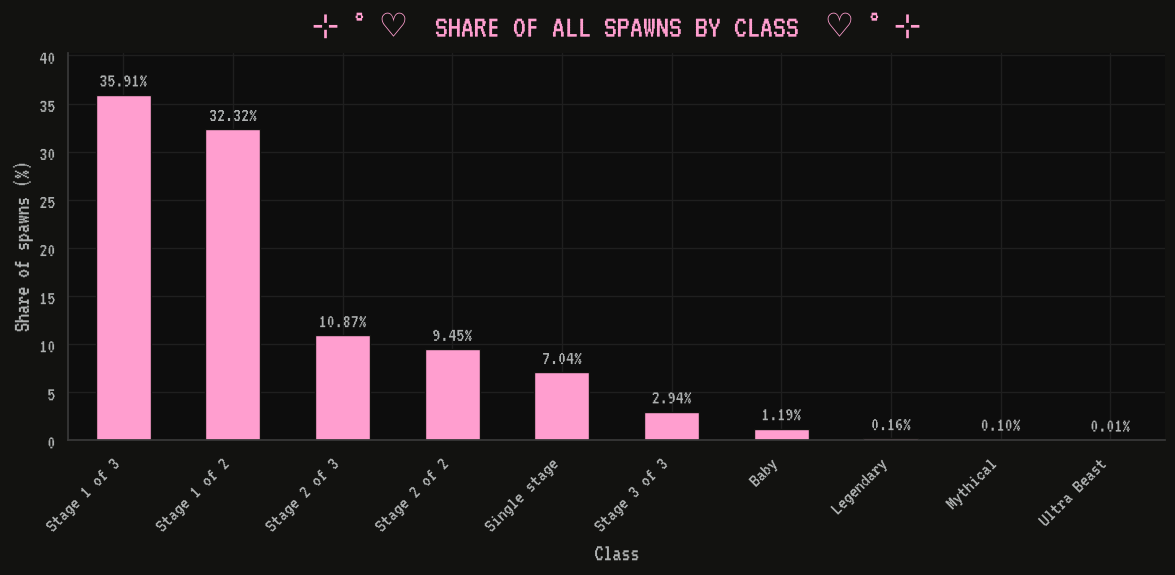

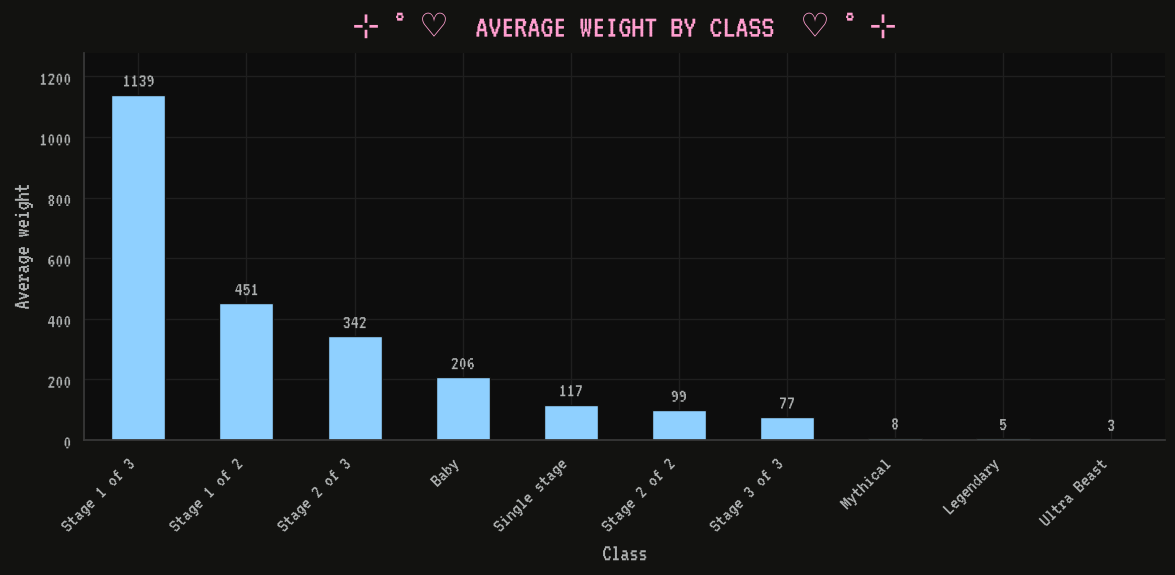

In [5]:
plt.figure(figsize=(12, 6))
class_summary['share_of_spawns'].sort_values(ascending=False).plot(kind='bar', color=PINK)
label_bars('%.2f%%')
plt.title('Share of All Spawns by Class')
plt.xlabel('Class')
plt.ylabel('Share of spawns (%)')
plt.xticks(rotation=45, ha='right')
decorate()
plt.show()

plt.figure(figsize=(12, 6))
class_summary['avg_weight'].sort_values(ascending=False).plot(kind='bar', color=BLUE)
label_bars('%.0f')
plt.title('Average Weight by Class')
plt.xlabel('Class')
plt.ylabel('Average weight')
plt.xticks(rotation=45, ha='right')
decorate()
plt.show()

### Classes

- First-stage species are about 68% of all spawns, 35.9% from three-stage lines and 32.3% from two-stage lines
- Fully evolved three-stage Pokémon are only 2.9%
- Baby Pokémon are their own class, 20 entries and 1.2% of spawns
- Average weight drops at every step of a line, about 1,139 for stage 1 of 3, 342 for stage 2 of 3 and 77 for stage 3 of 3

## Legendary, Mythical and Ultra Beast odds

In [6]:
rarity_order = ['Normal', 'Legendary', 'Mythical', 'Ultra Beast']

rarity_summary = pd.DataFrame({
    'species': df.groupby('rarity_group').size(),
    'total_weight': df.groupby('rarity_group')['weight'].sum(),
    'avg_weight': df.groupby('rarity_group')['weight'].mean(),
}).reindex(rarity_order)

rarity_summary['share_of_spawns'] = rarity_summary['total_weight'] / total_weight * 100
rarity_summary['one_every_n_spawns'] = total_weight / rarity_summary['total_weight']
rarity_summary.round(3)

,species,total_weight,avg_weight,share_of_spawns,one_every_n_spawns
rarity_group,,,,,
Normal,1159,344878,297.565,99.724,1.003
Legendary,105,560,5.333,0.162,617.559
Mythical,47,362,7.702,0.105,955.340
Ultra Beast,11,33,3.000,0.010,10479.788


In [7]:
# How many rare species sit at each weight
rare_df = df[df['rarity_group'] != 'Normal']
pd.pivot_table(
    rare_df,
    index='rarity_group',
    columns='weight',
    values='id',
    aggfunc='count',
    fill_value=0,
)

weight,1,2,3,6,10,12,24
rarity_group,,,,,,,
Legendary,18,9,2,71,2,0,3
Mythical,18,0,0,2,2,24,1
Ultra Beast,0,0,11,0,0,0,0


### Rarity

- About 99.7% of spawns are normal Pokémon
- A Legendary shows up about once every 618 spawns, a Mythical once every 955 and an Ultra Beast once every 10,480
- Most Legendaries sit at weight 6 and most Mythicals at weight 12, so a single Mythical is usually twice as likely as a single Legendary
- Legendaries still show up more as a group because there are 105 of them against 47 Mythicals
- Each group also has 18 entries at weight 1, for Mythicals these are Arceus and its type forms

## Spawn rates by region

There is no region multiplier in the spawn code, so any difference comes from how many heavy species a region has

In [8]:
region_order = [
    'Kanto', 'Johto', 'Hoenn', 'Sinnoh', 'Unova', 'Kalos',
    'Alola', 'Galar', 'Hisui', 'Paldea', 'Kitakami',
]

region_summary = pd.DataFrame({
    'species': df.groupby('region').size(),
    'total_weight': df.groupby('region')['weight'].sum(),
    'avg_weight': df.groupby('region')['weight'].mean(),
}).reindex(region_order)

region_summary['share_of_spawns'] = region_summary['total_weight'] / total_weight * 100
region_summary['one_every_n_spawns'] = total_weight / region_summary['total_weight']
region_summary.round(2)

,species,total_weight,avg_weight,share_of_spawns,one_every_n_spawns
region,,,,,
Kanto,153,58542,382.63,16.93,5.91
Johto,128,27802,217.20,8.04,12.44
Hoenn,141,42540,301.70,12.30,8.13
Sinnoh,139,22224,159.88,6.43,15.56
Unova,170,55020,323.65,15.91,6.29
Kalos,118,21923,185.79,6.34,15.77
Alola,128,19535,152.62,5.65,17.70
Galar,178,25248,141.84,7.30,13.70
Hisui,23,606,26.35,0.18,570.68


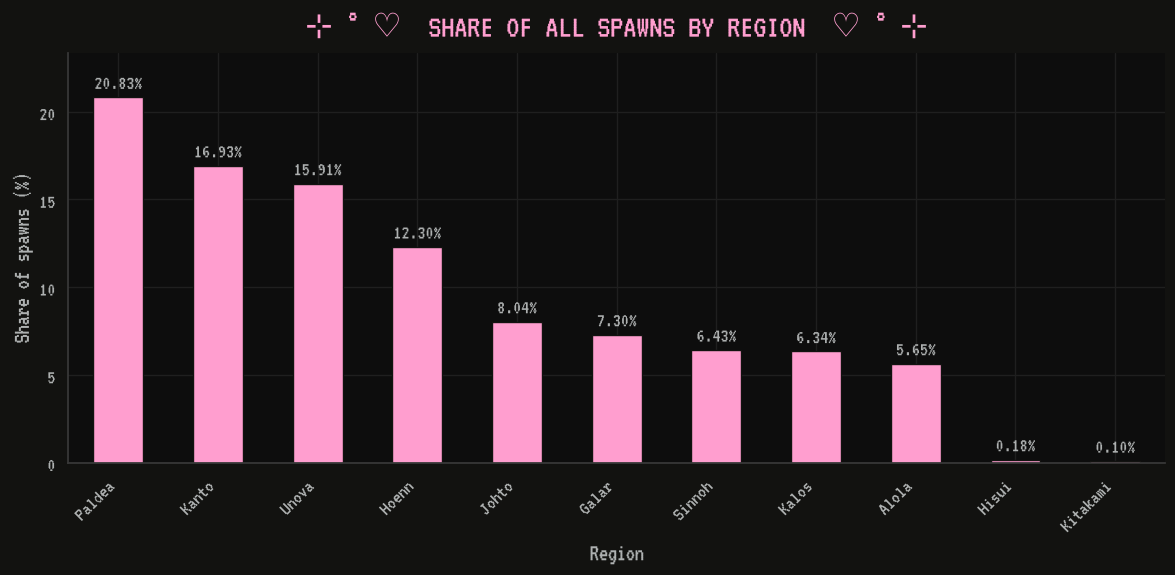

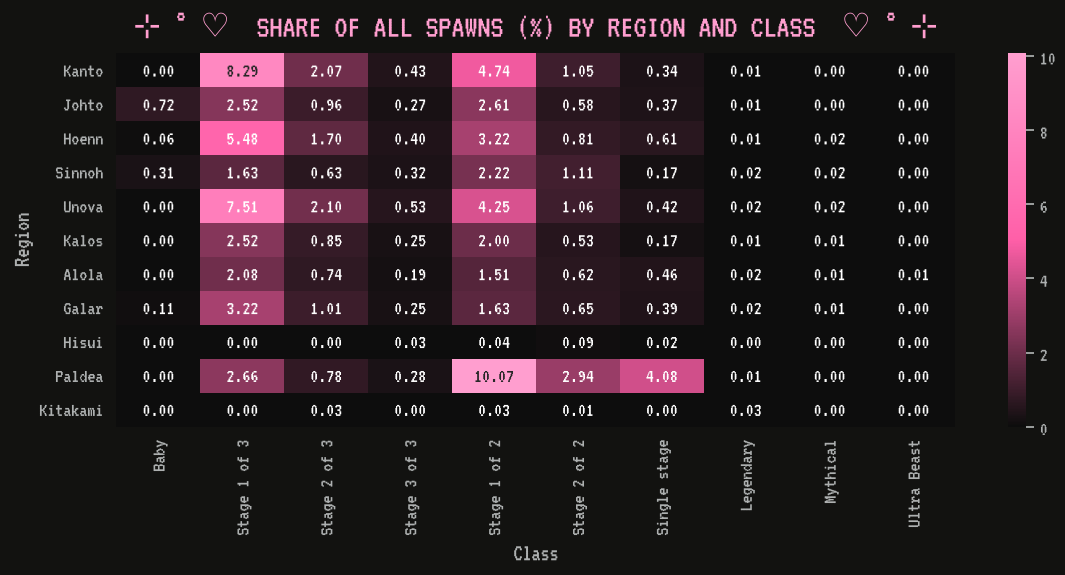

In [9]:
plt.figure(figsize=(12, 6))
region_summary['share_of_spawns'].sort_values(ascending=False).plot(kind='bar', color=PINK)
label_bars('%.2f%%')
plt.title('Share of All Spawns by Region')
plt.xlabel('Region')
plt.ylabel('Share of spawns (%)')
plt.xticks(rotation=45, ha='right')
decorate()
plt.show()

region_class = pd.pivot_table(
    df,
    index='region',
    columns='class',
    values='spawn_chance',
    aggfunc='sum',
    fill_value=0,
)
region_class = region_class.reindex(index=region_order, columns=class_order) * 100

fig, ax = plt.subplots(figsize=(12, 6))
pink_scale = sns.blend_palette([PANEL, DEEP_PINK, PINK], as_cmap=True)
sns.heatmap(region_class, annot=True, fmt='.2f', ax=ax, cmap=pink_scale)
ax.set_title('Share of All Spawns (%) by Region and Class')
ax.set_xlabel('Class')
ax.set_ylabel('Region')
ax.grid(False)
decorate()
plt.show()

### Regions

- Paldea has the largest share at 20.8% of spawns, followed by Kanto 16.9% and Unova 15.9%
- Alola 5.6% Kalos 6.3% and Sinnoh 6.4% are the lowest of the main regions
- Paldea's two-stage first forms alone are about 10% of all spawns
- Galar has the most catchable entries 178 but a low average weight, because many of them are low-weight forms

## Spawn rates by type

A dual-type species counts under both of its types, so these shares add up to more than 100 percent

In [10]:
# One row per species per type
type_df = pd.concat([
    df[['name', 'type_1', 'weight']].rename(columns={'type_1': 'type'}),
    df[['name', 'type_2', 'weight']].rename(columns={'type_2': 'type'}),
])
type_df = type_df.dropna(subset=['type'])
type_df = type_df[type_df['type'] != '???']

type_summary = pd.DataFrame({
    'species': type_df.groupby('type').size(),
    'total_weight': type_df.groupby('type')['weight'].sum(),
    'avg_weight': type_df.groupby('type')['weight'].mean(),
})

type_summary['share_of_spawns'] = type_summary['total_weight'] / total_weight * 100
type_summary['one_every_n_spawns'] = total_weight / type_summary['total_weight']
type_summary = type_summary.sort_values('share_of_spawns', ascending=False)
type_summary.round(2)

,species,total_weight,avg_weight,share_of_spawns,one_every_n_spawns
type,,,,,
Normal,163,50619,310.55,14.64,6.83
Water,172,48282,280.71,13.96,7.16
Grass,146,44443,304.40,12.85,7.78
Flying,143,36311,253.92,10.50,9.52
Bug,118,34990,296.53,10.12,9.88
Poison,94,32047,340.93,9.27,10.79
Rock,85,26256,308.89,7.59,13.17
Psychic,145,25402,175.19,7.35,13.61
Ground,89,25092,281.93,7.26,13.78


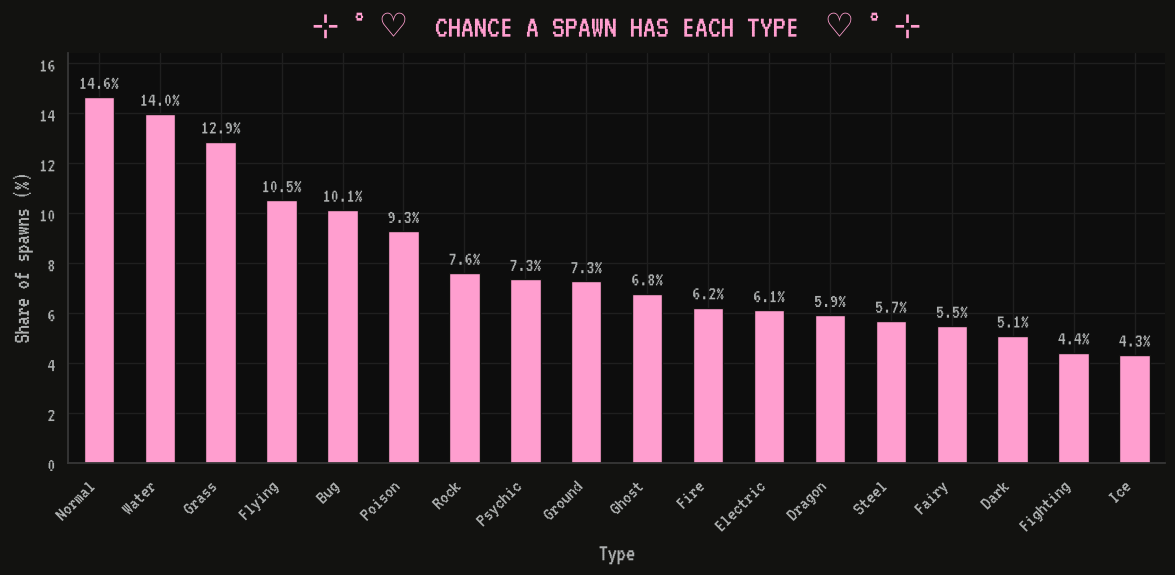

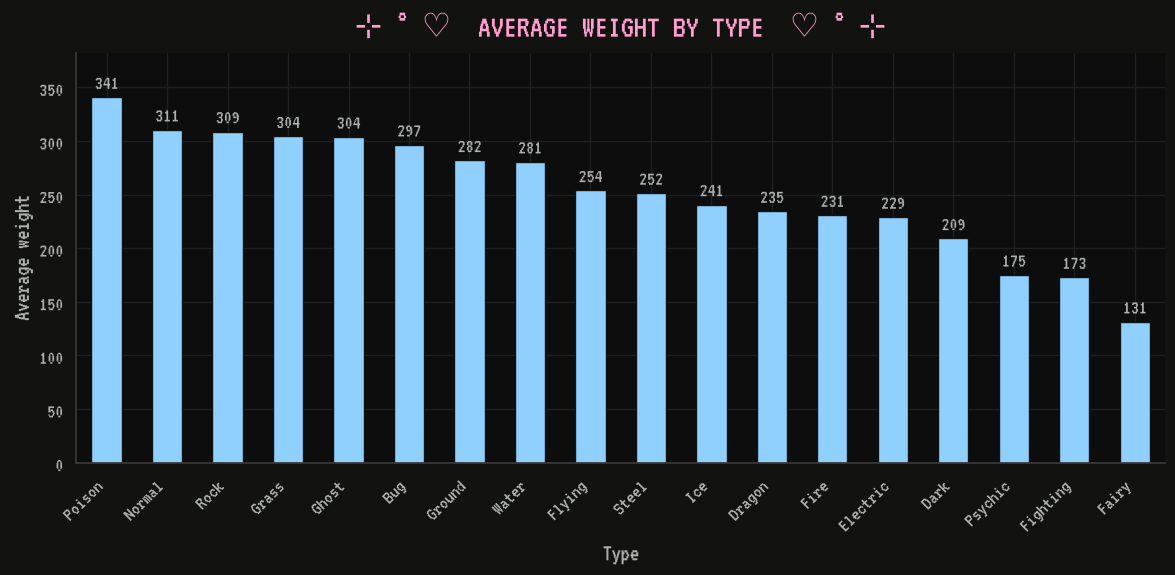

In [11]:
plt.figure(figsize=(12, 6))
type_summary['share_of_spawns'].sort_values(ascending=False).plot(kind='bar', color=PINK)
label_bars('%.1f%%')
plt.title('Chance a Spawn Has Each Type')
plt.xlabel('Type')
plt.ylabel('Share of spawns (%)')
plt.xticks(rotation=45, ha='right')
decorate()
plt.show()

plt.figure(figsize=(12, 6))
type_summary['avg_weight'].sort_values(ascending=False).plot(kind='bar', color=BLUE)
label_bars('%.0f')
plt.title('Average Weight by Type')
plt.xlabel('Type')
plt.ylabel('Average weight')
plt.xticks(rotation=45, ha='right')
decorate()
plt.show()

### Types

- Normal 14.6% Water 14.0% and Grass 12.9% are the types most likely to appear
- Ice 4.3% and Fighting 4.4% are the least likely
- Fairy and Psychic have plenty of species 144 and 145 but low average weights, so they show up less than their species counts suggest

## Weight tiers

In [12]:
tier_summary = pd.DataFrame({
    'species': df.groupby('weight').size(),
    'total_weight': df.groupby('weight')['weight'].sum(),
})

tier_summary['share_of_spawns'] = tier_summary['total_weight'] / total_weight * 100
tier_summary['one_in_n_per_species'] = total_weight / tier_summary.index
tier_summary = tier_summary.sort_index(ascending=False)

print('Distinct weights:', len(tier_summary))
tier_summary.round(2)

Distinct weights: 26


,species,total_weight,share_of_spawns,one_in_n_per_species
weight,,,,
1536,94,144384,41.75,225.15
1024,10,10240,2.96,337.73
512,33,16896,4.89,675.46
384,316,121344,35.09,900.61
308,5,1540,0.45,1122.83
288,3,864,0.25,1200.81
256,15,3840,1.11,1350.91
128,3,384,0.11,2701.82
96,433,41568,12.02,3602.43


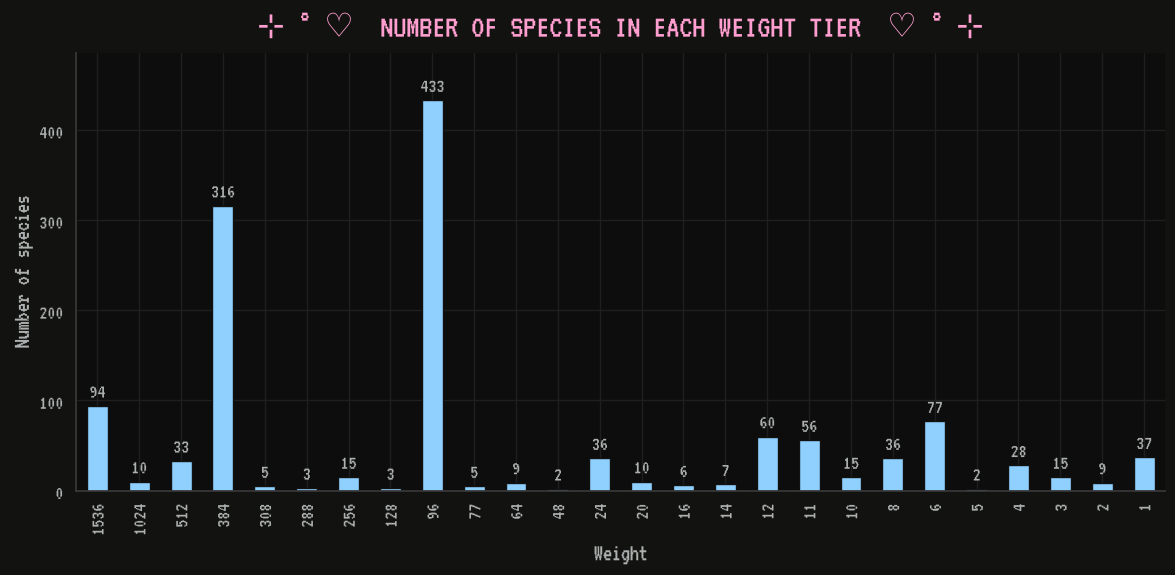

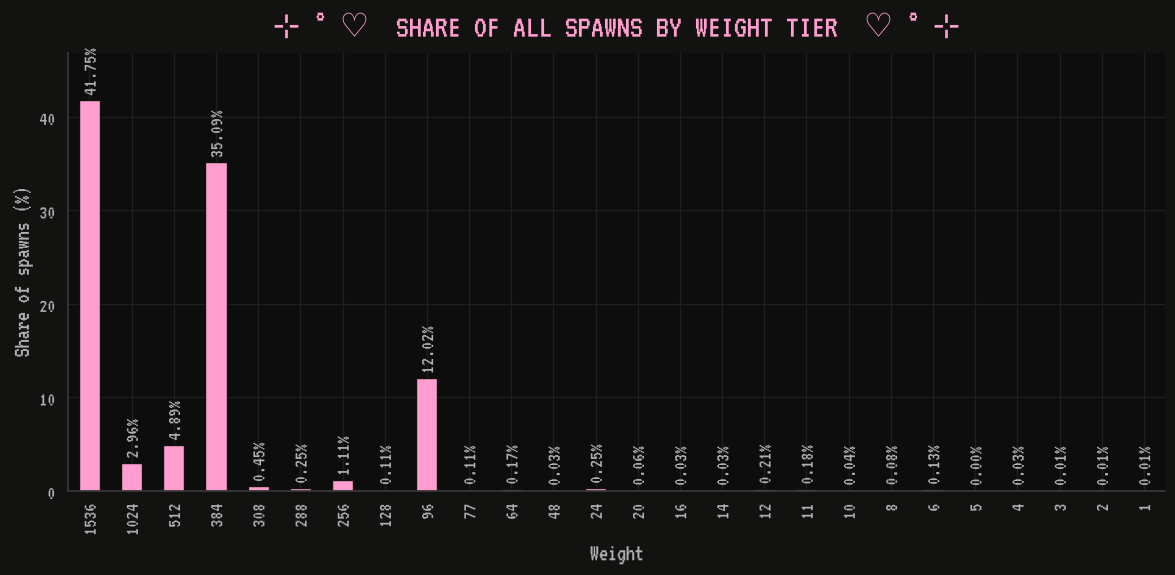

In [13]:
plt.figure(figsize=(12, 6))
tier_summary['species'].plot(kind='bar', color=BLUE)
label_bars('%d')
plt.title('Number of Species in Each Weight Tier')
plt.xlabel('Weight')
plt.ylabel('Number of species')
decorate()
plt.show()

plt.figure(figsize=(12, 6))
tier_summary['share_of_spawns'].plot(kind='bar', color=PINK)
label_bars('%.2f%%', rotation=90)
plt.title('Share of All Spawns by Weight Tier')
plt.xlabel('Weight')
plt.ylabel('Share of spawns (%)')
decorate()
plt.show()

### Weight tiers

- There are only 26 distinct weights
- 1536, 384 and 96 together cover 843 species and about 89% of all spawns
- The 94 species at weight 1536 alone are 41.8% of spawns
- Everything at weight 24 or below adds up to about 1% of spawns across 394 entries

## Most common and rarest species

In [14]:
cols = ['name', 'class', 'region', 'weight', 'one_in_n']

print('Species at the top weight:', (df['weight'] == df['weight'].max()).sum())
df.sort_values(['weight', 'id'], ascending=[False, True])[cols].head(10).round(0)

Species at the top weight: 94


,name,class,region,weight,one_in_n
9,Caterpie,Stage 1 of 3,Kanto,1536,225.0
12,Weedle,Stage 1 of 3,Kanto,1536,225.0
15,Pidgey,Stage 1 of 3,Kanto,1536,225.0
28,Nidoran♀️,Stage 1 of 3,Kanto,1536,225.0
31,Nidoran♂️,Stage 1 of 3,Kanto,1536,225.0
40,Zubat,Stage 1 of 3,Kanto,1536,225.0
42,Oddish,Stage 1 of 3,Kanto,1536,225.0
59,Poliwag,Stage 1 of 3,Kanto,1536,225.0
62,Abra,Stage 1 of 3,Kanto,1536,225.0
65,Machop,Stage 1 of 3,Kanto,1536,225.0


In [15]:
df.sort_values(['weight', 'id'])[cols].head(15).round(0)

,name,class,region,weight,one_in_n
1488,MissingNo.,Single stage,???,1,345833.0
492,Arceus,Mythical,Sinnoh,1,345833.0
772,Silvally,Legendary,Alola,1,345833.0
1371,Bug Arceus,Mythical,Sinnoh,1,345833.0
1372,Dark Arceus,Mythical,Sinnoh,1,345833.0
1373,Dragon Arceus,Mythical,Sinnoh,1,345833.0
1374,Electric Arceus,Mythical,Sinnoh,1,345833.0
1375,Fighting Arceus,Mythical,Sinnoh,1,345833.0
1376,Fire Arceus,Mythical,Sinnoh,1,345833.0
1377,Flying Arceus,Mythical,Sinnoh,1,345833.0


## Scenario analysis: how long until something rare

Each spawn is independent, so the chance of at least one hit in `n` spawns is `1 - (1 - p) ** n`. The public bot code spawns once every 24 counted messages per server

In [16]:
messages_per_spawn = 24

group_chance = rarity_summary['total_weight'] / total_weight

scenario_df = pd.DataFrame([
    {'target': 'Any Legendary', 'chance_per_spawn': group_chance['Legendary']},
    {'target': 'Any Mythical', 'chance_per_spawn': group_chance['Mythical']},
    {'target': 'Any Ultra Beast', 'chance_per_spawn': group_chance['Ultra Beast']},
    {'target': 'One specific weight 6 Legendary', 'chance_per_spawn': 6 / total_weight},
])

scenario_df['expected_spawns'] = 1 / scenario_df['chance_per_spawn']
scenario_df['spawns_for_50_percent'] = np.log(0.5) / np.log(1 - scenario_df['chance_per_spawn'])
scenario_df['spawns_for_90_percent'] = np.log(0.1) / np.log(1 - scenario_df['chance_per_spawn'])
scenario_df['expected_messages'] = scenario_df['expected_spawns'] * messages_per_spawn
scenario_df.round({
    'chance_per_spawn': 6,
    'expected_spawns': 0,
    'spawns_for_50_percent': 0,
    'spawns_for_90_percent': 0,
    'expected_messages': 0,
})

,target,chance_per_spawn,expected_spawns,spawns_for_50_percent,spawns_for_90_percent,expected_messages
0,Any Legendary,0.001619,618.0,428.0,1421.0,14821.0
1,Any Mythical,0.001047,955.0,662.0,2199.0,22928.0
2,Any Ultra Beast,0.000095,10480.0,7264.0,24129.0,251515.0
3,One specific weight 6 Legendary,0.000017,57639.0,39952.0,132717.0,1383332.0


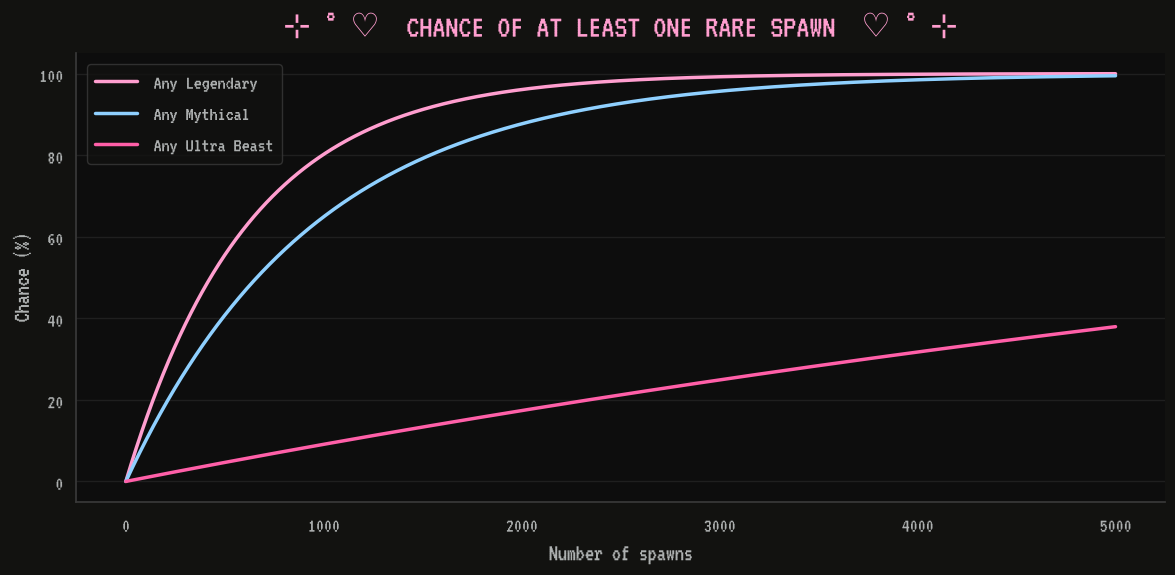

In [17]:
spawns = np.arange(0, 5001)

plt.figure(figsize=(12, 6))
for i in range(3):
    p = scenario_df['chance_per_spawn'][i]
    plt.plot(spawns, (1 - (1 - p) ** spawns) * 100, label=scenario_df['target'][i], linewidth=2.5)
plt.title('Chance of at Least One Rare Spawn')
plt.xlabel('Number of spawns')
plt.ylabel('Chance (%)')
plt.legend()
decorate()
plt.show()

### Wait times

- Any Legendary takes about 618 spawns on average, roughly 14,800 counted messages at 24 messages per spawn
- There is a 50% chance of seeing one within 428 spawns and a 90% chance within 1,421
- One specific weight 6 Legendary takes about 57,600 spawns, roughly 1.4 million counted messages
- Counted messages are rate limited per user and per server, so real chat volume would be higher

## Regression: what explains a species' weight

The weights run from 1 to 1536, so the target is `log2(weight)`. The data is split 60/40 into training and validation sets

In [18]:
model_df = df[df['type_1'] != '???'].copy()
model_df['log2_weight'] = np.log2(model_df['weight'])

features = [
    'stage', 'chain_length', 'base_stat_total', 'is_form',
    'legendary', 'mythical', 'ultra_beast',
    'region', 'type_1',
]
outcome = 'log2_weight'

X = pd.get_dummies(model_df[features], drop_first=True, dtype=int)
y = model_df[outcome]

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)
train_X.shape, valid_X.shape

((792, 35), (529, 35))

In [19]:
linear_model = LinearRegression().fit(train_X, train_y)

lasso_cv = Pipeline([
    ('scale', StandardScaler(with_mean=False)),
    ('model', LassoCV(max_iter=10000, random_state=1, cv=5)),
])

lasso_cv.fit(train_X, train_y)

# Baseline that always predicts the training mean
baseline_pred = [train_y.mean()] * len(valid_y)

print('Baseline RMSE:', round(np.sqrt(mean_squared_error(valid_y, baseline_pred)), 3))
print('Linear RMSE:', round(np.sqrt(mean_squared_error(valid_y, linear_model.predict(valid_X))), 3))
print('Linear R2:', round(r2_score(valid_y, linear_model.predict(valid_X)), 3))
print('Lasso RMSE:', round(np.sqrt(mean_squared_error(valid_y, lasso_cv.predict(valid_X))), 3))
print('Lasso R2:', round(r2_score(valid_y, lasso_cv.predict(valid_X)), 3))

print('\nLasso alpha:', lasso_cv['model'].alpha_)
print(pd.Series(lasso_cv['model'].coef_, index=train_X.columns))

Baseline RMSE: 2.58
Linear RMSE: 1.107
Linear R2: 0.816
Lasso RMSE: 1.093
Lasso R2: 0.821

Lasso alpha: 0.02333665554028909
stage             -0.760019
chain_length       0.942702
base_stat_total   -0.539721
is_form           -0.995492
legendary         -0.828865
mythical          -0.378795
ultra_beast       -0.401435
region_Galar      -0.000000
region_Hisui      -0.016562
region_Hoenn       0.050213
region_Johto      -0.101240
region_Kalos      -0.013178
region_Kanto       0.077710
region_Kitakami    0.069925
region_Paldea      0.367320
region_Sinnoh      0.000000
region_Unknown    -0.000000
region_Unova       0.143260
type_1_Dark       -0.000000
type_1_Dragon      0.107378
type_1_Electric    0.000000
type_1_Fairy      -0.071988
type_1_Fighting   -0.013378
type_1_Fire        0.000000
type_1_Flying      0.052247
type_1_Ghost      -0.000000
type_1_Grass       0.000000
type_1_Ground     -0.000000
type_1_Ice         0.000000
type_1_Normal      0.029239
type_1_Poison      0.018677
type_1_P

Predictors kept by Lasso: 24 of 35


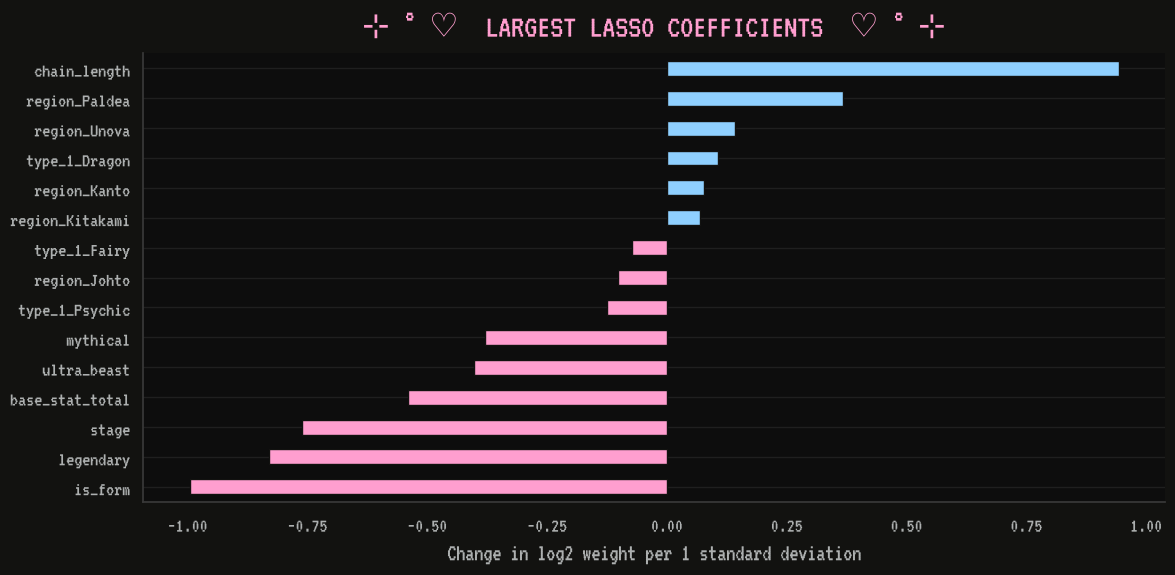

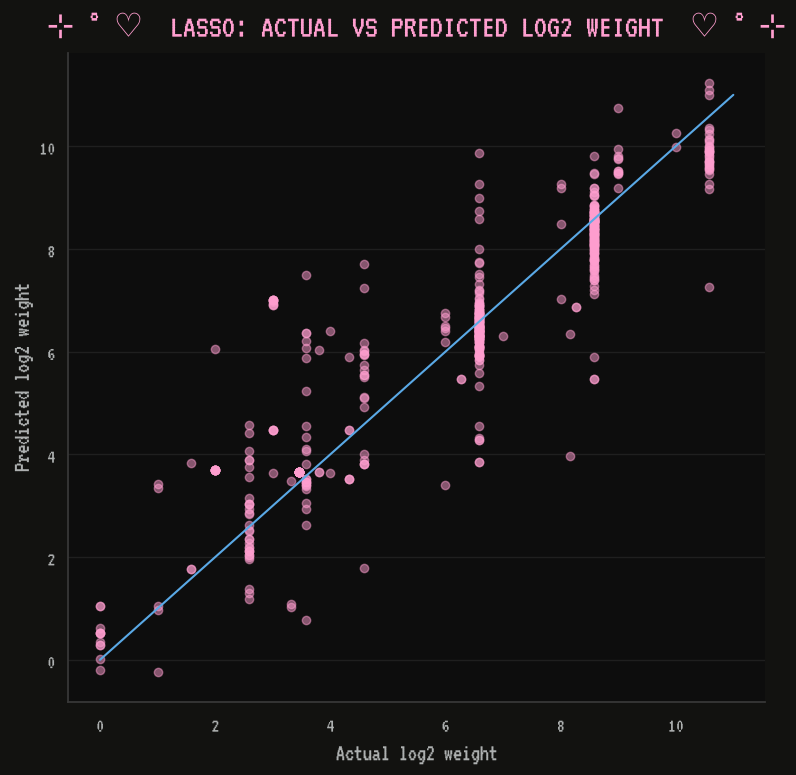

In [20]:
lasso_coefs = pd.Series(lasso_cv['model'].coef_, index=train_X.columns)
kept = lasso_coefs[lasso_coefs != 0]
print('Predictors kept by Lasso:', len(kept), 'of', len(lasso_coefs))

top_coefs = kept[kept.abs().sort_values(ascending=False).index].head(15).sort_values()

plt.figure(figsize=(12, 6))
top_coefs.plot(kind='barh', color=[PINK if c < 0 else BLUE for c in top_coefs])
plt.title('Largest Lasso Coefficients')
plt.grid(axis='x')
plt.xlabel('Change in log2 weight per 1 standard deviation')
decorate()
plt.show()

plt.figure(figsize=(8, 8))
plt.scatter(valid_y, lasso_cv.predict(valid_X), color=PINK, alpha=0.5)
plt.plot([0, 11], [0, 11], color=DEEP_BLUE)
plt.title('Lasso: Actual vs Predicted log2 Weight')
plt.xlabel('Actual log2 weight')
plt.ylabel('Predicted log2 weight')
decorate()
plt.show()

### Regression

- Lasso reached a validation RMSE of about 1.09 in log2 units with an R² of 0.82
- Plain linear regression was almost the same at 1.11 and 0.816, and the mean baseline was 2.58
- An error of 1.1 in log2 units means a typical prediction is off by about a factor of two, roughly one weight tier
- Lasso kept 24 of 35 predictors
- Being an alternate form, being later in an evolution line, being Legendary and having a higher base stat total all push weight down, while a longer evolution line pushes it up
- Region and type barely matter once those are accounted for, Paldea is the one clear exception

## Decision tree: learning the tiers as rules

A decision tree splits the data with yes or no questions, so it can copy the tier structure directly instead of fitting one straight line

In [21]:
tree_model = DecisionTreeRegressor(max_depth=4, random_state=1)
tree_model.fit(train_X, train_y)

print('Tree RMSE:', round(np.sqrt(mean_squared_error(valid_y, tree_model.predict(valid_X))), 3))
print('Tree R2:', round(r2_score(valid_y, tree_model.predict(valid_X)), 3))

# The first few questions the tree asks
print(export_text(tree_model, feature_names=list(train_X.columns), max_depth=3))

Tree RMSE: 1.289
Tree R2: 0.75
|--- base_stat_total <= 551.00
|   |--- is_form <= 0.50
|   |   |--- base_stat_total <= 409.50
|   |   |   |--- legendary <= 0.50
|   |   |   |   |--- value: [8.88]
|   |   |   |--- legendary >  0.50
|   |   |   |   |--- value: [2.58]
|   |   |--- base_stat_total >  409.50
|   |   |   |--- region_Paldea <= 0.50
|   |   |   |   |--- value: [6.66]
|   |   |   |--- region_Paldea >  0.50
|   |   |   |   |--- value: [8.39]
|   |--- is_form >  0.50
|   |   |--- region_Paldea <= 0.50
|   |   |   |--- region_Unova <= 0.50
|   |   |   |   |--- value: [3.67]
|   |   |   |--- region_Unova >  0.50
|   |   |   |   |--- value: [7.08]
|   |   |--- region_Paldea >  0.50
|   |   |   |--- type_1_Fighting <= 0.50
|   |   |   |   |--- value: [8.47]
|   |   |   |--- type_1_Fighting >  0.50
|   |   |   |   |--- value: [3.58]
|--- base_stat_total >  551.00
|   |--- is_form <= 0.50
|   |   |--- stage <= 2.50
|   |   |   |--- base_stat_total <= 568.50
|   |   |   |   |--- value: 

### Decision tree

- A depth 4 tree scored a validation RMSE of 1.29 and an R² of 0.75, worse than Lasso at 1.10 and 0.82
- Its first question is whether base stat total is above 551, then whether the Pokémon is an alternate form
- Several leaves predict 2.58, which is log2 of 6, the usual Legendary weight
- A depth 4 tree has at most 16 leaves, so it can only predict 16 different values, which is too coarse on its own

## Random forest and cross-validation

A random forest averages many deep trees, each trained on a random resample of the rows. One 60/40 split can be lucky or unlucky, so every model is also scored on 5 different splits

In [22]:
forest_model = RandomForestRegressor(n_estimators=500, random_state=1)
forest_model.fit(train_X, train_y)

print('Forest RMSE:', round(np.sqrt(mean_squared_error(valid_y, forest_model.predict(valid_X))), 3))
print('Forest R2:', round(r2_score(valid_y, forest_model.predict(valid_X)), 3))

Forest RMSE: 0.875
Forest R2: 0.885


In [23]:
folds = KFold(n_splits=5, shuffle=True, random_state=1)

models = {
    'Linear': LinearRegression(),
    'Lasso': Pipeline([
        ('scale', StandardScaler(with_mean=False)),
        ('model', LassoCV(max_iter=10000, random_state=1, cv=5)),
    ]),
    'Decision tree': DecisionTreeRegressor(max_depth=4, random_state=1),
    'Random forest': RandomForestRegressor(n_estimators=500, random_state=1),
}

results = []

for name, model in models.items():
    scores = -cross_val_score(model, X, y, cv=folds, scoring='neg_root_mean_squared_error')

    results.append({
        'model': name,
        'mean_rmse': scores.mean(),
        'std_rmse': scores.std(),
        'best_fold': scores.min(),
        'worst_fold': scores.max()
    })

cv_df = pd.DataFrame(results)
cv_df.round(3)

,model,mean_rmse,std_rmse,best_fold,worst_fold
0,Linear,1.105,0.097,0.977,1.276
1,Lasso,1.101,0.090,0.972,1.255
2,Decision tree,1.226,0.045,1.162,1.292
3,Random forest,0.776,0.088,0.640,0.889


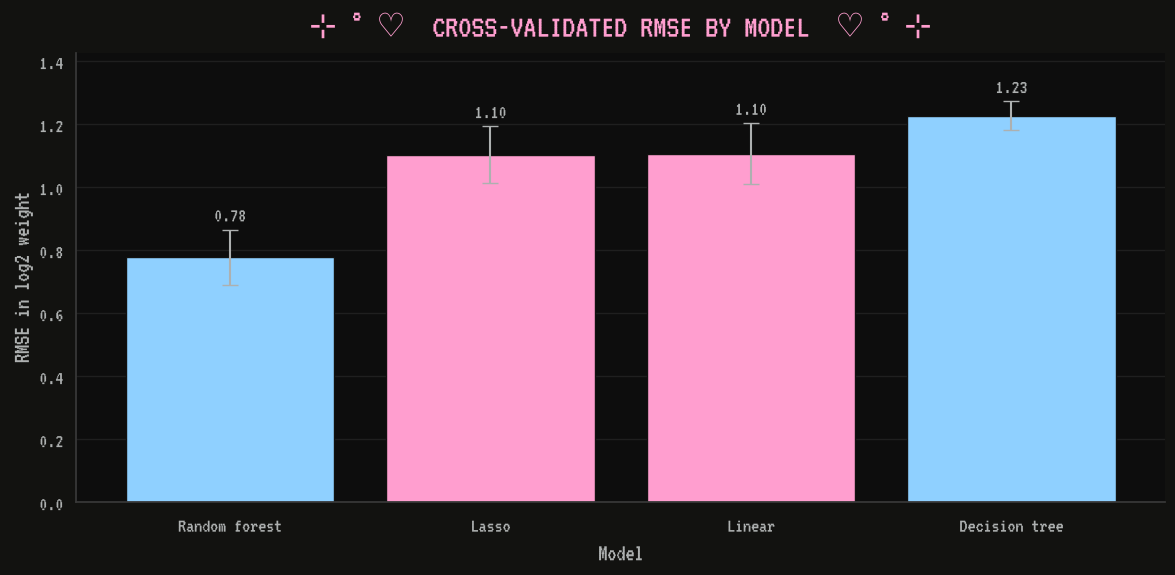

In [24]:
plt.figure(figsize=(12, 6))
# Best model first, tree models in blue
cv_sorted = cv_df.sort_values('mean_rmse')
colors = [BLUE if model in ['Decision tree', 'Random forest'] else PINK for model in cv_sorted['model']]

plt.bar(
    cv_sorted['model'],
    cv_sorted['mean_rmse'],
    yerr=cv_sorted['std_rmse'],
    color=colors,
    capsize=6,
    ecolor=TEXT,
)
label_bars('%.2f')
plt.title('Cross-Validated RMSE by Model')
plt.xlabel('Model')
plt.ylabel('RMSE in log2 weight')
decorate()
plt.show()

### Forest and cross-validation

- The random forest scored a validation RMSE of 0.88 and an R² of 0.885, the best of any model here
- Across 5 folds the forest averaged an RMSE of 0.78, against 1.10 for Lasso and linear and 1.23 for the single tree
- One model's score moves by about 0.09 from fold to fold, so the tiny gap between linear and Lasso is not a real difference
- The forest's worst fold 0.89 still beat Lasso's best fold 0.97, so that gap is real

## Permutation importance

Shuffle one column at a time in the validation data and see how much worse the forest gets. A big jump in error means the model relies on that column

base_stat_total    1.455
is_form            0.909
legendary          0.358
chain_length       0.352
region_Paldea      0.263
stage              0.179
region_Unova       0.079
region_Johto       0.064
ultra_beast        0.031
region_Hoenn       0.028
dtype: float64


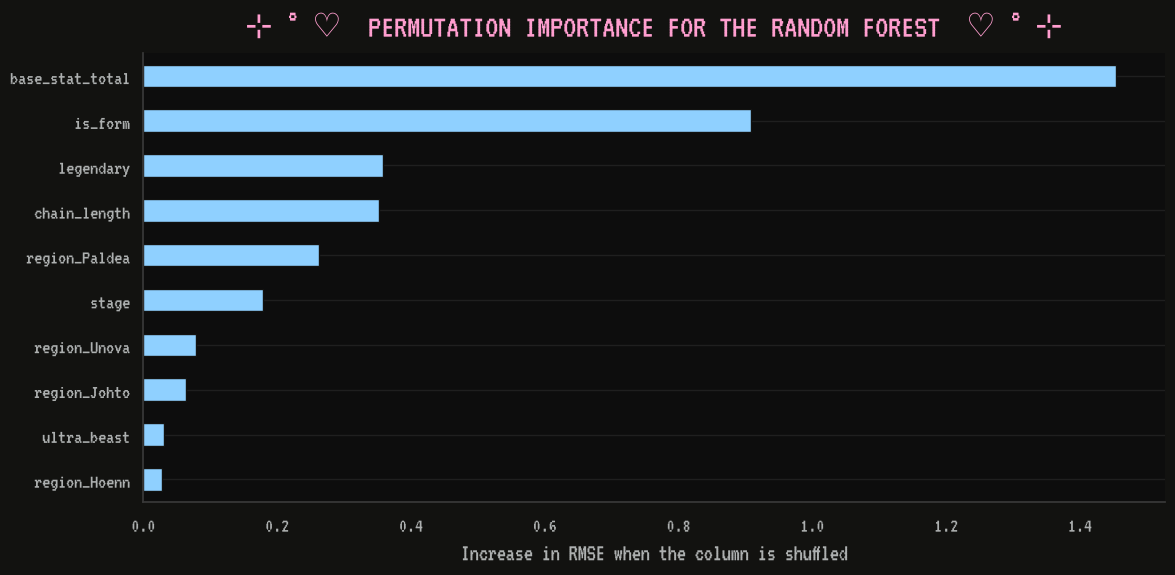

In [25]:
perm = permutation_importance(
    forest_model,
    valid_X,
    valid_y,
    n_repeats=20,
    random_state=1,
    scoring='neg_root_mean_squared_error',
)
perm_importance = pd.Series(perm.importances_mean, index=valid_X.columns).sort_values(ascending=False)
print(perm_importance.head(10).round(3))

plt.figure(figsize=(12, 6))
perm_importance.head(10).sort_values().plot(kind='barh', color=BLUE)
plt.title('Permutation Importance for the Random Forest')
plt.xlabel('Increase in RMSE when the column is shuffled')
plt.grid(axis='x')
decorate()
plt.show()

### Importance

- Base stat total matters most, shuffling it raises RMSE by 1.46
- The form flag is second at 0.91, then Legendary 0.36, chain length 0.35 and Paldea 0.26
- Stage only adds 0.18 here even though Lasso ranked it high, likely because base stat total already carries much of the same information
- No type column makes the top 10

## Classification: can stats alone flag a rare spawn

A species is rare here if its weight is 24 or less. The model only sees base stat total, stage, chain length and the form flag. The Legendary, Mythical and Ultra Beast flags are left out on purpose because they would give the answer away

In [26]:
model_df['is_rare'] = (model_df['weight'] <= 24).astype(int)
print('Rare species:', model_df['is_rare'].sum(), 'of', len(model_df))

rare_train, rare_test = train_test_split(model_df, test_size=0.4, random_state=1)

rare_formula = 'is_rare ~ base_stat_total + stage + chain_length + is_form'
rare_model = smf.glm(rare_formula, data=rare_train, family=sm.families.Binomial()).fit()

print(rare_model.summary())

Rare species: 393 of 1321
                 Generalized Linear Model Regression Results                  
Dep. Variable:                is_rare   No. Observations:                  792
Model:                            GLM   Df Residuals:                      787
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -184.14
Date:                Sat, 10 Oct 2026   Deviance:                       368.29
Time:                        15:51:21   Pearson chi2:                 3.54e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.5207
Covariance Type:            nonrobust                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       

In [27]:
test_prob = rare_model.predict(rare_test[['base_stat_total', 'stage', 'chain_length', 'is_form']])
test_pred = (test_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(rare_test['is_rare'], test_pred).ravel()
metrics = {
    'accuracy': accuracy_score(rare_test['is_rare'], test_pred),
    'recall': recall_score(rare_test['is_rare'], test_pred),
    'specificity': tn / (tn + fp),
    'precision': precision_score(rare_test['is_rare'], test_pred),
    'f1_score': f1_score(rare_test['is_rare'], test_pred),
}
metrics

{'accuracy': 0.9187145557655955,
 'recall': 0.8121212121212121,
 'specificity': np.float64(0.967032967032967),
 'precision': 0.9178082191780822,
 'f1_score': 0.8617363344051447}

In [28]:
# Test different probability thresholds
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for t in thresholds:
    preds = (test_prob >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(rare_test['is_rare'], preds).ravel()

    results.append({
        'threshold': t,
        'accuracy': accuracy_score(rare_test['is_rare'], preds),
        'recall': recall_score(rare_test['is_rare'], preds),
        'specificity': tn / (tn + fp),
        'precision': precision_score(rare_test['is_rare'], preds),
        'f1_score': f1_score(rare_test['is_rare'], preds)
    })

threshold_df = pd.DataFrame(results)

print("Threshold Performance Comparison:")
display(threshold_df.round(3))

Threshold Performance Comparison:


,threshold,accuracy,recall,specificity,precision,f1_score
0,0.1,0.824,0.939,0.772,0.651,0.769
1,0.2,0.894,0.897,0.893,0.791,0.841
2,0.3,0.930,0.885,0.951,0.890,0.888
3,0.4,0.928,0.861,0.959,0.904,0.882
4,0.5,0.919,0.812,0.967,0.918,0.862
5,0.6,0.894,0.721,0.973,0.922,0.810
6,0.7,0.839,0.545,0.973,0.900,0.679


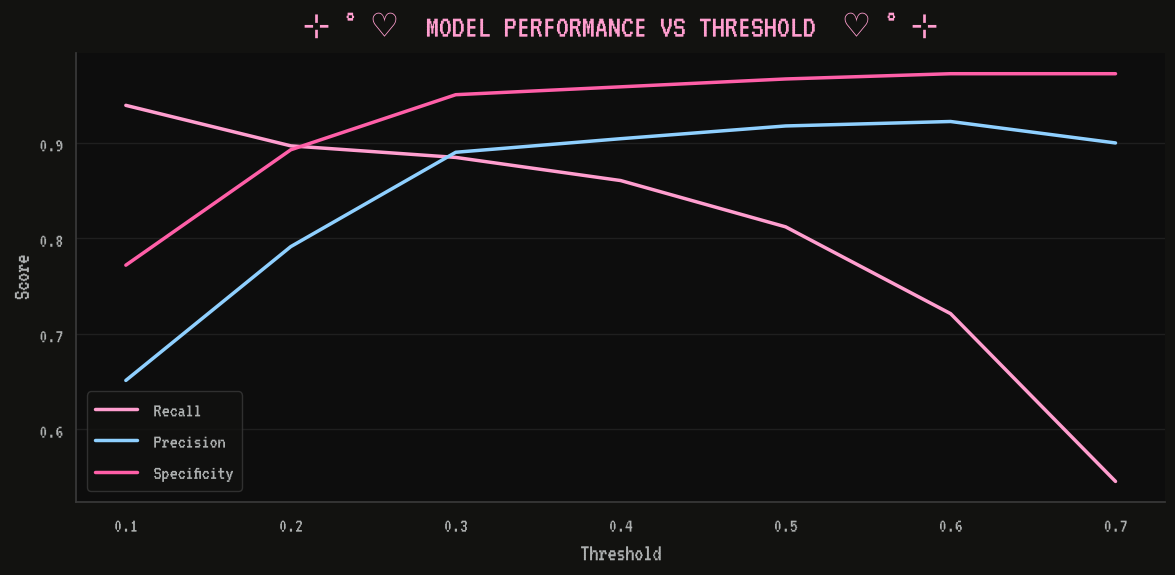

In [29]:
# Visualization
plt.figure(figsize=(12, 6))

plt.plot(threshold_df['threshold'], threshold_df['recall'], label='Recall', linewidth=2.5)
plt.plot(threshold_df['threshold'], threshold_df['precision'], label='Precision', linewidth=2.5)
plt.plot(threshold_df['threshold'], threshold_df['specificity'], label='Specificity', linewidth=2.5)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Model Performance vs Threshold")

plt.legend()
decorate()
plt.show()

### Classification

- About 30% of entries are rare, so always guessing not rare would be about 70% accurate
- At the default 0.50 threshold the model reached 91.9% accuracy with 81.2% recall and 91.8% precision
- A threshold of 0.30 gave the best accuracy 93.0% and raised recall to 88.5%
- At 0.10 the model catches 93.9% of rare species but precision falls to 65.1%
- Base stat total and the form flag are the significant predictors, stage and chain length are not significant at the 5% level
- So rare spawns are mostly either strong Pokémon or alternate forms

## Export for the lookup tool

In [30]:
import json

lookup_df = df[['dex_number', 'name', 'slug', 'region', 'type_1', 'type_2', 'class', 'weight']].copy()
lookup_df['type_2'] = lookup_df['type_2'].fillna('')

lookup = {
    'total_weight': int(total_weight),
    'messages_per_spawn': messages_per_spawn,
    'pokemon': lookup_df.to_dict('records'),
}

with open(DATA_PATH / 'data' / 'spawn_lookup.json', 'w', encoding='utf-8') as f:
    json.dump(lookup, f, ensure_ascii=False)

print('Exported species:', len(lookup_df))

Exported species: 1322


## Summary

Main takeaways:
- Spawns are random but not uniformly random, each species has a fixed weight
- First-stage Pokémon are about 68% of spawns and fully evolved three-stage Pokémon about 3%
- Legendary, Mythical and Ultra Beast spawns together are under 0.3% of the pool
- There is no region multiplier, Paldea leads only because it has many heavy first-stage species
- Evolution structure, base stats and form status explain about 82% of the variation in log weight
- A random forest does better than the linear models, explaining about 88% on the same validation split

Limitations:
- The live bot loads its data from a private repository, so real weights may differ from this public CSV
- Eight species are season-locked, which this analysis ignores
- Pokémon whose only earlier form is a baby count as single stage, like Lucario and Snorlax
- Paradox Pokémon have no flag in the source and fall under single stage